In [1]:
import os
from getpass import getpass
os.environ["TMDB_API_KEY"] = "9bc46329bd12d593e26807ea2f38e6c6"

# La clave se lee del entorno; si no esta, la pide (no queda guardada en el notebook).
if not os.environ.get("TMDB_API_KEY"):
    os.environ["TMDB_API_KEY"] = getpass("TMDB_API_KEY: ")

In [2]:
"""
Dataset v2: solo decada 2010-2019, ~2000 carteles, 512x768 (2:3).

Uso:
    Ejecuta la celda de la clave y luego esta celda.

Los carteles se bajan en w780 y se reducen a 512x768 (recorte centrado minimo
a proporcion 2:3 + LANCZOS), asi nunca se amplia la imagen.
Reanudable: reutiliza raw/*.json y posters ya generados.
"""
import argparse
import hashlib
import io
import json
import os
import random
import sys
import time
from pathlib import Path

import pandas as pd
import requests
from PIL import Image

API = "https://api.themoviedb.org/3"
IMG = "https://image.tmdb.org/t/p/w780"
SIZE = (512, 768)

GENRES = {
    "terror": 27,
    "comedia": 35,
    "ciencia_ficcion": 878,
    "romance": 10749,
    "animacion": 16,
    "accion": 28,
}
TARGET_IDS = set(GENRES.values())
START, END = 2010, 2019

SEED = 42
MIN_WORDS = 20
MIN_VOTES = 10


def get(session, path, params, retries=5):
    for attempt in range(retries):
        r = session.get(f"{API}{path}", params=params, timeout=20)
        if r.status_code == 429:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        time.sleep(0.05)
        return r.json()
    raise RuntimeError(f"Demasiados 429 en {path}")


def valid(movie, genre_id):
    ids = set(movie.get("genre_ids", []))
    if ids & TARGET_IDS != {genre_id}:
        return False
    if not movie.get("poster_path"):
        return False
    if len((movie.get("overview") or "").split()) < MIN_WORDS:
        return False
    return movie.get("original_language") == "en"


def discover_genre(session, genre_id, n, pool_pages, rng):
    pool = []
    for page in range(1, pool_pages + 1):
        data = get(session, "/discover/movie", {
            "with_genres": genre_id,
            "with_original_language": "en",
            "vote_count.gte": MIN_VOTES,
            "primary_release_date.gte": f"{START}-01-01",
            "primary_release_date.lte": f"{END}-12-31",
            "sort_by": "vote_count.desc",
            "include_adult": "false",
            "page": page,
        })
        pool += [m for m in data["results"] if valid(m, genre_id)]
        if page >= min(data.get("total_pages", 1), 500):
            break
    rng.shuffle(pool)
    return pool[:n]


def save_poster(session, poster_path, dest):
    """Descarga w780, recorta a 2:3 y reduce a 512x768."""
    if dest.exists():
        return True
    r = session.get(f"{IMG}{poster_path}", timeout=30)
    if r.status_code != 200:
        return False
    im = Image.open(io.BytesIO(r.content)).convert("RGB")
    w, h = im.size
    tw, th = SIZE
    if w * th > h * tw:      # demasiado ancha: recorta lados
        nw = round(h * tw / th)
        x = (w - nw) // 2
        im = im.crop((x, 0, x + nw, h))
    else:                    # demasiado alta: recorta arriba/abajo
        nh = round(w * th / tw)
        y = (h - nh) // 2
        im = im.crop((0, y, w, y + nh))
    im = im.resize(SIZE, Image.LANCZOS)
    im.save(dest, "JPEG", quality=92)
    return True


def assign_split(group_key):
    h = int(hashlib.md5(f"{SEED}-{group_key}".encode()).hexdigest(), 16) % 100
    if h < 10:
        return "holdout_gen"
    if h < 80:
        return "train"
    if h < 90:
        return "val"
    return "test"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--per-genre", type=int, default=340)
    ap.add_argument("--pool-pages", type=int, default=120)
    ap.add_argument("--out", default="data_v2")
    args, _ = ap.parse_known_args()

    key = os.environ.get("TMDB_API_KEY")
    if not key:
        sys.exit("Falta la variable de entorno TMDB_API_KEY")

    out = Path(args.out)
    (out / "posters").mkdir(parents=True, exist_ok=True)
    (out / "raw").mkdir(parents=True, exist_ok=True)

    session = requests.Session()
    session.params = {"api_key": key}  # type: ignore[assignment]
    rng = random.Random(SEED)

    rows, seen = [], set()
    for genre, gid in GENRES.items():
        cands = discover_genre(session, gid, args.per_genre, args.pool_pages, rng)
        print(f"{genre:16s}: {len(cands)} candidatas", flush=True)
        for m in cands:
            mid = m["id"]
            if mid in seen:
                continue
            seen.add(mid)

            raw_file = out / "raw" / f"{mid}.json"
            if raw_file.exists():
                detail = json.loads(raw_file.read_text(encoding="utf-8"))
            else:
                detail = get(session, f"/movie/{mid}", {"append_to_response": "keywords"})
                raw_file.write_text(json.dumps(detail, ensure_ascii=False), encoding="utf-8")

            if not save_poster(session, detail.get("poster_path"), out / "posters" / f"{mid}.jpg"):
                print(f"  ! cartel no descargado: {mid}", flush=True)
                continue

            coll = detail.get("belongs_to_collection") or {}
            group = coll.get("id") or f"m{mid}"
            rows.append({
                "tmdb_id": mid,
                "title": detail.get("title"),
                "year": (detail.get("release_date") or "")[:4],
                "genre": genre,
                "overview": detail.get("overview"),
                "tagline": detail.get("tagline"),
                "keywords": "|".join(k["name"] for k in detail.get("keywords", {}).get("keywords", [])),
                "collection": coll.get("name"),
                "poster_file": f"posters/{mid}.jpg",
                "split": assign_split(group),
            })

    df = pd.DataFrame(rows).drop_duplicates("tmdb_id")
    df.to_csv(out / "metadata.csv", index=False, encoding="utf-8")
    print(f"\nListo: {len(df)} peliculas en {out / 'metadata.csv'}")
    print(df.groupby("genre").size().to_string())
    print(df.groupby("split").size().to_string())


if __name__ == "__main__":
    main()

terror          : 340 candidatas
comedia         : 340 candidatas
ciencia_ficcion : 340 candidatas
romance         : 340 candidatas
animacion       : 292 candidatas
accion          : 340 candidatas

Listo: 1992 peliculas en data_v2/metadata.csv
genre
accion             340
animacion          292
ciencia_ficcion    340
comedia            340
romance            340
terror             340
split
holdout_gen     229
test            206
train          1359
val             198


genre
terror             340
comedia            340
ciencia_ficcion    340
romance            340
animacion          292
accion             340
split
holdout_gen     229
test            206
train          1359
val             198


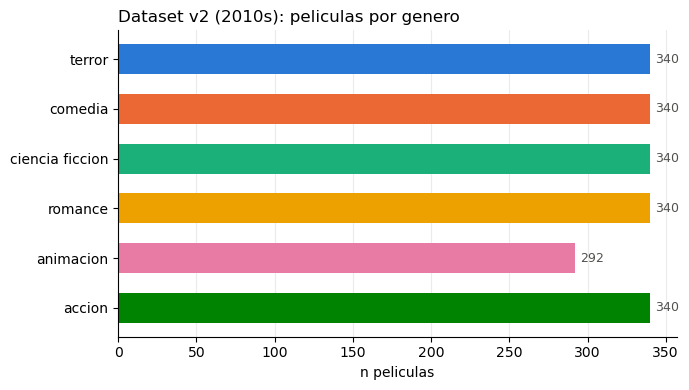

In [3]:
import matplotlib.pyplot as plt

df = pd.read_csv("data_v2/metadata.csv")
generos = ["terror", "comedia", "ciencia_ficcion", "romance", "animacion", "accion"]
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

print(df.groupby("genre").size().reindex(generos).to_string())
print(df.groupby("split").size().to_string())

tot = df["genre"].value_counts().reindex(generos)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([g.replace("_", " ") for g in generos], tot.values, color=colores, height=0.6)
for i, v in enumerate(tot.values):
    ax.text(v + tot.max() * 0.01, i, int(v), va="center", fontsize=9, color="#52514e")
ax.invert_yaxis()
ax.set_title("Dataset v2 (2010s): peliculas por genero", loc="left")
ax.set_xlabel("n peliculas")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [4]:
from collections import Counter
from pathlib import Path
from PIL import Image

tamanos = Counter()
for f in Path("data_v2/posters").glob("*.jpg"):
    with Image.open(f) as im:
        tamanos[im.size] += 1

print(f"{sum(tamanos.values())} imagenes")
for (w, h), n in tamanos.most_common():
    print(f"{w}x{h}: {n}  (ratio {w / h:.3f})")


1992 imagenes
512x768: 1992  (ratio 0.667)
